# Teleconnections

## Figure 15: tropical North Atlantic response

In [1]:
import json
from pathlib import Path
import cmip6_results
import matplotlib.pyplot as plt
import numpy as np
import plotstyle as ps

ps.apply()

In [2]:
DATA = Path("../data")
BINS = [(-np.inf, -2), (-2, -1.5), (-1.5, -1), (-1, -0.5), (0.5, 1), (1, 1.5), (1.5, 2), (2, np.inf)]


def pooled(sources: dict, members: list[str], phase: str) -> tuple[np.ndarray, np.ndarray, int]:
    parts = [sources[m]["composites"][phase] for m in members if m in sources]
    parts = [p for p in parts if p["n"] > 1]
    n = np.array([p["n"] for p in parts], dtype=float)
    means = np.array([p["mean"] for p in parts])
    errs = np.array([p["stderr"] for p in parts])
    mean = (means * n[:, None]).sum(0) / n.sum()
    err = np.sqrt(((errs * n[:, None]) ** 2).sum(0)) / n.sum()
    return mean, err, int(n.sum())


def bin_means(ax, points: np.ndarray, colour: str) -> None:
    centres, means, errs = [], [], []
    for lo, hi in BINS:
        sel = (points[:, 0] >= lo) & (points[:, 0] < hi)
        if sel.sum() >= 2:
            centres.append(np.median(points[sel, 0]))
            means.append(points[sel, 1].mean())
            errs.append(points[sel, 1].std(ddof=1) / np.sqrt(sel.sum()))
    ax.errorbar(centres, means, yerr=errs, color=colour, lw=1.8, marker="o", ms=4,
                capsize=0, elinewidth=1.2, zorder=5)


def month_axis(ax) -> None:
    ticks = np.arange(3, 24, 3)
    names = {3: "MAM", 6: "JJA", 9: "SON", 0: "DJF"}
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{names[t % 12]}\n({'0' if t <= 12 else '+1'})" for t in ticks])
    ax.axvspan(14.5, 15.5, color=ps.GRID, alpha=0.6, lw=0, zorder=0)
    ax.axvline(12, color=ps.INK, lw=0.8, ls=":", zorder=1)
    ax.axhline(0, color=ps.INK, lw=0.8, zorder=1)
    ax.set_xlim(3, 23)

In [3]:
results = json.loads((DATA / "tna_composites.json").read_text())
sources = results["sources"]
lags = np.array(results["lags"])
entries = ps.present(sources)
cmip6 = cmip6_results.component("tna")
colour6 = ps.COLORS["CMIP6"]

def band(ax, x, rows, label=None):
    rows = np.asarray(rows, dtype=float)
    lo, hi = np.nanpercentile(rows, [10, 90], axis=0)
    ax.fill_between(x, lo, hi, color=colour6, alpha=0.25, lw=0, zorder=1)
    ax.plot(x, np.nanmean(rows, axis=0), color=colour6, lw=1.8, zorder=3, label=label)

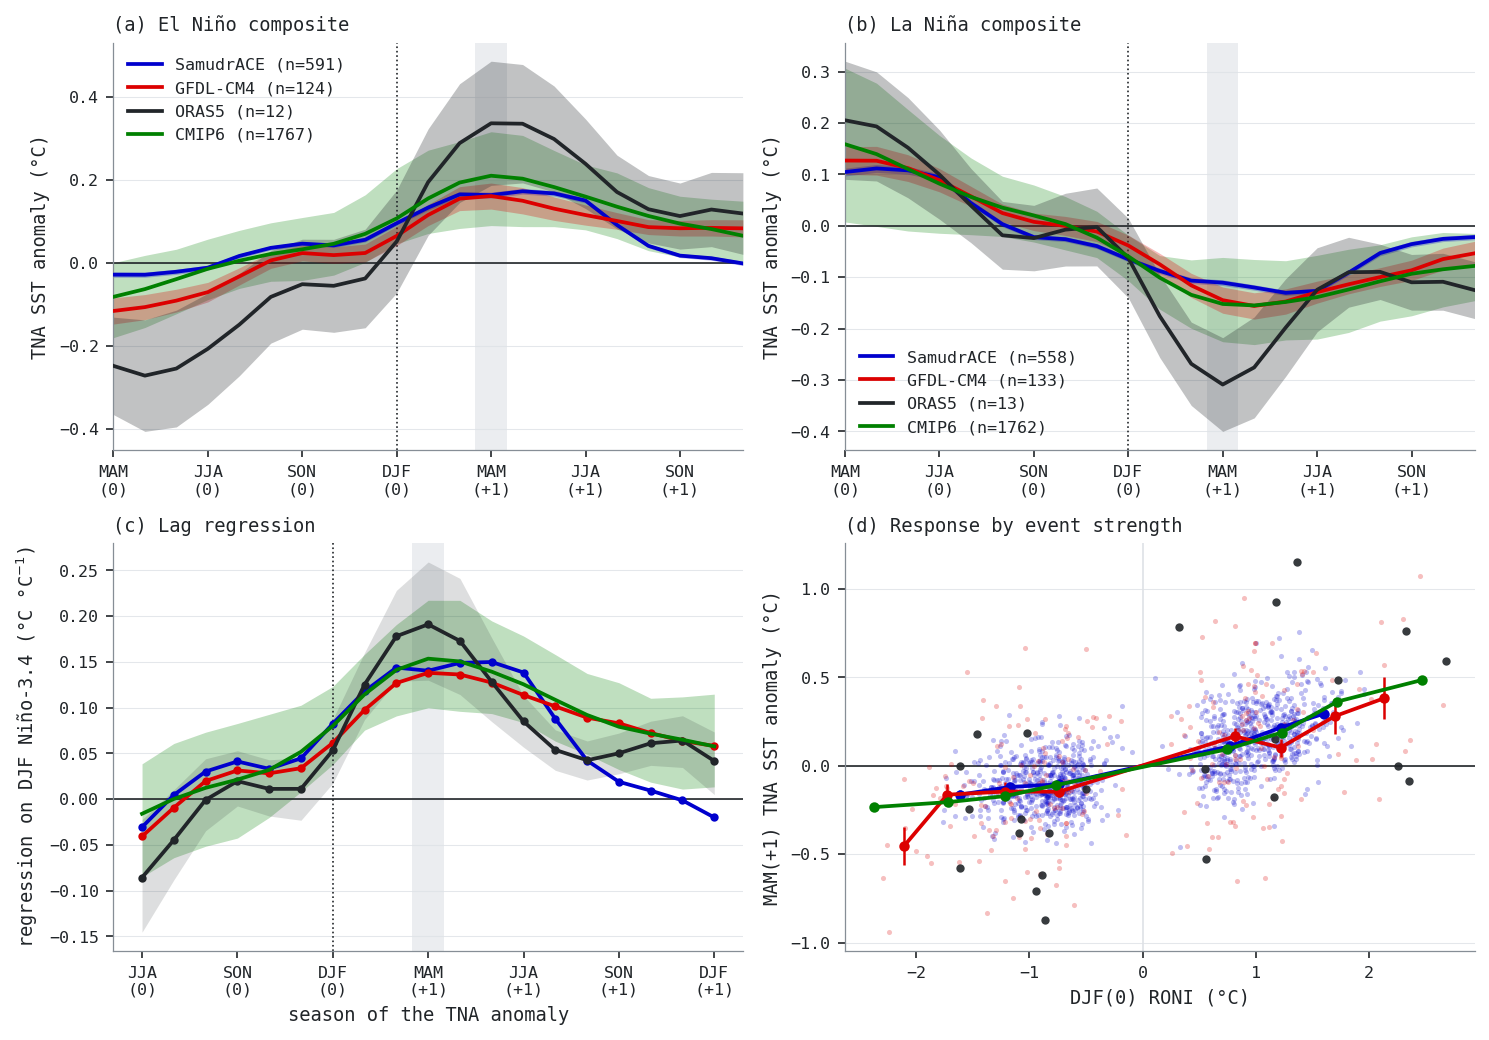

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10.0, 7.0))
axes = axes.ravel()
marks = ps.letters(4)
x = np.arange(24)

for ax, phase, label, mark in (
    (axes[0], "elnino", "El Niño composite", marks[0]),
    (axes[1], "lanina", "La Niña composite", marks[1]),
):
    for key in entries:
        mean, err, n = pooled(sources, ps.members(key), phase)
        colour = ps.COLORS[key]
        ax.fill_between(x, mean - err, mean + err, color=colour, alpha=0.28, lw=0, zorder=2)
        ax.plot(x, mean, color=colour, lw=1.8, zorder=3, label=f"{ps.LABELS[key]} (n={n})")
    if cmip6:
        parts = [c["composites"][phase] for c in cmip6.values()
                 if c["composites"][phase]["n"] > 1]
        band(ax, x, [c["mean"] for c in parts],
             f"CMIP6 (n={sum(c['n'] for c in parts)})")
    month_axis(ax)
    ax.set_ylabel("TNA SST anomaly (°C)")
    ps.panel_label(ax, label, mark)
    ps.tidy(ax)
    ax.legend(loc="upper left" if phase == "elnino" else "lower left")

ax = axes[2]
for key in entries:
    slopes = np.mean(
        [sources[m]["lag_regression"] for m in ps.members(key) if m in sources], axis=0
    )
    ax.plot(lags, slopes, color=ps.COLORS[key], lw=1.8, marker="o", ms=3, zorder=3)
if cmip6:
    band(ax, lags, [c["lag_regression"] for c in cmip6.values()])
boot = ps.obs_bootstrap("tna")
if "lag_regression" in boot:
    ps.obs_band(ax, lags, boot["lag_regression"])
ax.axhline(0, color=ps.INK, lw=0.8, zorder=1)
ax.axvspan(2.5, 3.5, color=ps.GRID, alpha=0.6, lw=0, zorder=0)
ax.axvline(0, color=ps.INK, lw=0.8, ls=":", zorder=1)
ax.set_xlabel("season of the TNA anomaly")
ax.set_ylabel("regression on DJF Niño-3.4 (°C °C$^{-1}$)")
lag_ticks = np.arange(-6, 13, 3)
seasons = {0: "DJF", 3: "MAM", 6: "JJA", 9: "SON"}
ax.set_xticks(lag_ticks)
ax.set_xticklabels([f"{seasons[(t + 12) % 12]}\n({(t + 11) // 12:+d})".replace("+0", "0")
                    for t in lag_ticks])
ps.panel_label(ax, "Lag regression", marks[2])
ps.tidy(ax)

ax = axes[3]
for key in entries:
    points = np.array(
        [p for m in ps.members(key) if m in sources for p in sources[m]["scatter"]]
    )
    if points.size == 0:
        continue
    colour = ps.COLORS[key]
    ax.scatter(
        points[:, 0],
        points[:, 1],
        s=6 if key != "ORAS5" else 16,
        color=colour,
        alpha=0.25 if key != "ORAS5" else 0.9,
        lw=0,
        zorder=2 if key != "ORAS5" else 4,
    )
    if key == "ORAS5":
        continue
    bin_means(ax, points, colour)
if cmip6:
    points = np.array([p for c in cmip6.values() for p in c["scatter"]])
    bin_means(ax, points, colour6)
ax.axhline(0, color=ps.INK, lw=0.8, zorder=1)
ax.axvline(0, color=ps.GRID, lw=0.8, zorder=1)
ax.set_xlabel("DJF(0) RONI (°C)")
ax.set_ylabel("MAM(+1) TNA SST anomaly (°C)")
ps.panel_label(ax, "Response by event strength", marks[3])
ps.tidy(ax)

fig.tight_layout()
ps.save(fig, Path("../figures/tna_composites"))